In [26]:
import sys
import numpy as np
import pandas as pd
import sklearn
print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__ )

3.12.7 2.0.2 2.3.3 1.6.1


In [27]:
from sklearn.model_selection import train_test_split

SEED = 2653

data = pd.read_csv("data/heart_disease.csv")
feature_names = [c for c in data.columns if c != "disease"]
X, y = data[feature_names].to_numpy(), data["disease"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)
print(data.shape, round(y.mean(), 3), X_train.shape, X_test.shape)

(297, 14) 0.461 (207, 13) (90, 13)


# part 1
## 1. Parent entropy

there are 12 pationts
6 p. have disease = 1
6 p. have disease = 0

p1 = 6/12 = 0.5
p2 = 6/12 = 0.5

H (parent) = -0.5 * log_2(0.5) - 0.5 * log_2(0.5)
           = -0.5 * (-1) - 0.5 * (-1) = 0.5 + 0.5 = 1 bit


## 2. infotmation gain
### 2.1 age 55 plus

Split:
age_55_plus  = 1: 6 p. , 5 disease, 1 healthy

p1 = 5/6, p0 = 1/6
H = -(5/6) * log_2(5/6) - (1/6) * log_2(1/6) = 0.650 bit

age_55_plus = 0: 6p. , 1 disease, 5 healthy

p1 = 1/6, p0 = 5/6
H = -(1/6) * log_2(1/6) - (5/6) * log_2(5/6) = 0.650 bit

weighted entropy = (6/12) * 0.650 + (6/12) * 0.650 = 0.650

IG = 1 - 0.650 = 0.350

### 2.2 exercise_angina

split:
exercise_angina = 1: 4p. , 4 diseased, 0 healthy

p1 = 4/4, p0 = 0/4
H = -1 * log_2(1) - 0 * log_2(0) = 0 bit

exercise_angina = 0: 8p. , 2 diseased, 6 healthy

p1 = 2/8, p0 = 6/8
H = -0.25 * log_2(0.25) - 0.75 * log_2(0.75) = 0.811 bit

w.entropy = 4/12 * 0 - 8/12 * 0.811 = 0.541

### 2.3 male

split:
male = 1: 6p. , 3 diseased, 3 healthy

p1 = 3/6, p0 = 3/6
H = -(3/6) * log_2(3/6) - (3/6) * log_2(3/6) = 1 bit

male = 0: 6p. , 3 diseased, 3 healthy (the same)
H = 1 bit

IG = 1 - 1 = 0 bit  (male doen't help)

### 2.4 hight_bp

split:
high_bp = 1: 6p. , 4 deseased, 2 healthy

p1 = 4/6, p0 = 2/6
H = -(4/6) * log_2(4/6) - (2/6) * log_2(2/6) = 0.918 bit

high_bp = 0: 6p. , 2 diseased, 4 healthy

p1 = 2/6, p0 = 4/6
H = -(2/6) * log_2(2/6) - (4/6) * log_2(4/6) = 0.918 bit

W.entropy = 0.5 * 0.918 + 0.5 * 0.918 = 0.918

IG = 1 - 0.918 = 0.082 bit

## 3 root
                    IG

age_55_plus =     0.350
exercise_angina = 0.459
male =            0.0
high_bp =         0.082

root of the tree "exercise_angina". It has a highest IG

## 4. inside the right branch

split:
age_55_plus = 1: 2p. , 1 d, 1h

p1 = 1/2, p0 = 1/2
H = -0.5 * log_2(0.5) - 0.5 * log(0.5) = 1

age_55_plus = 0: 6p. , 1d, 5h

p1 = 1/6, p0 = 5/6
H = -(1/6) * log_2(1/6) - (5/6) * log_2(5/6) = 0.650

w.entr = (2/8) * 1 + (6/8) * 0.650 = 0.738
IG = 0.811 - 0.738 = 0.073


split:
male = 1: 3p. , 0d, 3h

p1 = 0/3, p0 = 3/3
H = 0 * log_2(0) - 1 * log_2(1) = 0

male = 0: 5p. , 2d, 3h

p1 = 2/5, p0 = 3/5
H = -(2/5) * log_2(2/5) - (3/5) * log_2(3/5) = 0.971

w.entr = (3/8) * 0 + (5/8) * 0.971 = 0.607
IG = 0.811 - 0.607 = 0.204


split:
high_bp = 1: 3p. , 1d, 2h

p1 = 1/3, p0 = 2/3
H = -(1/3) * log_2(1/3) - (2/3) * log_2(2/3) = 0.918

high_bp = 0: 5p. , 1d, 4h

p1 = 1/5, p0 = 4/5
H = -(1/5) * log_2(1/5) - (4/5) * log_2(4/5) = 0.722

w.entr = (3/8) * 0.918 + (5/8) * 0.722 = 0.795
IG = 0.811 - 0.795 = 0.016


IG:
male = 0.204
age_55_plus = 0.073
high_bp = 0.016

chosen feature inside the branch iy's "male"


# Part 2

In [2]:
def entropy(y):
    """ Entropy in bits of an array of integer class labels."""
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probs = counts / len(y)
    return -np.sum(probs * np.log2(probs, where=probs > 0)) 

In [11]:
toy = pd.DataFrame({
    "age_55_plus":     [1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0],
    "exercise_angina": [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
    "male":            [1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0],
    "high_bp":         [1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0],
    "disease":         [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
})

print("H(parent) =", entropy(toy["disease"].to_numpy()))


left  = toy["exercise_angina"] == 1   
right = toy["exercise_angina"] == 0   
print("H(exercise_angina=1) =", entropy(toy.loc[left,  "disease"].to_numpy()))
print("H(exercise_angina=0) =", entropy(toy.loc[right, "disease"].to_numpy()))

H(parent) = 1.0
H(exercise_angina=1) = -0.0
H(exercise_angina=0) = 0.8112781244591328


In [9]:
def information_gain(y, left):
    """ Entropy of y minus the size-weighted entropy of y[left] and y[~left]; left is a boolean mask."""
    H_parent = entropy(y)
    H_left = entropy(y[left])
    H_right = entropy(y[~left])
    w_left = np.sum(left) / len(y)
    w_right = np.sum(~left) / len(y)
    w_entropy = w_left * H_left + w_right * H_right
    return H_parent - w_entropy

In [12]:
y = toy["disease"].to_numpy()

print("H(parent) =", entropy(y))
print()

left = (toy["age_55_plus"] == 1).to_numpy()
print(f"age_55_plus:     IG = {information_gain(y, left):.3f}")

left = (toy["exercise_angina"] == 1).to_numpy()
print(f"exercise_angina: IG = {information_gain(y, left):.3f}")

left = (toy["male"] == 1).to_numpy()
print(f"male:            IG = {information_gain(y, left):.3f}")

left = (toy["high_bp"] == 1).to_numpy()
print(f"high_bp:         IG = {information_gain(y, left):.3f}")

H(parent) = 1.0

age_55_plus:     IG = 0.350
exercise_angina: IG = 0.459
male:            IG = 0.000
high_bp:         IG = 0.082


In [15]:
def best_split(X, y, min_samples_leaf=1):
    """Return (feature_index, threshold, gain) of the best split, or None if no valid split exists."""
    best = None
    best_gain = -1.0

    for feature_idx in range(X.shape[1]):
        values = X[:, feature_idx]
        thresholds = (np.unique(values)[:-1] + np.unique(values)[1:]) / 2

        for threshold in thresholds:
            left = values <= threshold

            if np.sum(left) < min_samples_leaf:
                continue
            if np.sum(~left) < min_samples_leaf:
                continue

            gain = information_gain(y, left)

            if gain > best_gain:
                best_gain = gain
                best = (feature_idx, float(threshold), float(gain))

    return best

In [16]:
X_toy = toy.drop(columns="disease").to_numpy()
y_toy = toy["disease"].to_numpy()

result = best_split(X_toy, y_toy)
print(result)

(1, 0.5, 0.4591479170272448)


In [34]:
def build_tree(X, y, max_depth=None, min_samples_leaf=1, depth=0):
    """Grow a tree recursively and return it as nested dicts."""

    if len(np.unique(y)) == 1:
        return {"leaf": int(y[0])}

    if max_depth is not None and depth >= max_depth:
        majority = int(np.argmax(np.bincount(y)))
        return {"leaf": majority}

    split = best_split(X, y, min_samples_leaf=min_samples_leaf)

    if split is None:
        majority = int(np.argmax(np.bincount(y)))
        return {"leaf": majority}


    feature_idx, threshold, _ = split
    left_mask = X[:, feature_idx] <= threshold

    left_child  = build_tree(X[left_mask],  y[left_mask],
                             max_depth=max_depth,
                             min_samples_leaf=min_samples_leaf,
                             depth=depth + 1)
    right_child = build_tree(X[~left_mask], y[~left_mask],
                             max_depth=max_depth,
                             min_samples_leaf=min_samples_leaf,
                             depth=depth + 1)

    return {
        "feature": feature_idx,
        "threshold": float(threshold),
        "left": left_child,
        "right": right_child,
    }

In [38]:
def predict_tree(tree, X):
    """Return one predicted label per row of X."""
    predictions = []
    for row in X:
        node = tree
        while "leaf" not in node:
            feature_idx = node["feature"]
            threshold = node["threshold"]
            if row[feature_idx] <= threshold:
                node = node["left"]
            else:
                node = node["right"]
        predictions.append(node["leaf"])
    return np.array(predictions)

In [32]:
from sklearn.tree import DecisionTreeClassifier

ref = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=SEED)
ref.fit(X_train, y_train)

print("sklearn feature:", feature_names[ref.tree_.feature[0]], "threshold:", ref.tree_.threshold[0])

our_split = best_split(X_train, y_train)
print("our best_split:", (feature_names[our_split[0]], our_split[1], our_split[2]))

sklearn feature: ca threshold: 0.5
our best_split: ('ca', 0.5, 0.18324542662794518)


In [39]:
depths = [1, 2, 3, 4, 5, None]
results = []

for d in depths:
   
    our_tree = build_tree(X_train, y_train, max_depth=d)
    our_preds = predict_tree(our_tree, X_test)

   
    sk_tree = DecisionTreeClassifier(
        criterion="entropy", max_depth=d, random_state=SEED
    ).fit(X_train, y_train)
    sk_preds = sk_tree.predict(X_test)

    agreement = (our_preds == sk_preds).mean()
    results.append((d, agreement))

for d, a in results:
    label = "None" if d is None else str(d)
    print(f"max_depth={label:>4}  agreement={a:.4f}")

max_depth=   1  agreement=1.0000
max_depth=   2  agreement=1.0000
max_depth=   3  agreement=1.0000
max_depth=   4  agreement=1.0000
max_depth=   5  agreement=0.9444
max_depth=None  agreement=1.0000


# Part 3 — How deep should the tree be?

In [40]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [42]:
model = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED)

scores = cross_validate(
    model, X_train, y_train,
    cv=cv,
    scoring="accuracy",
    return_train_score=True
)

print("Train accuracy (mean):", scores["train_score"].mean().round(4))
print("CV accuracy (mean):   ", scores["test_score"].mean().round(4))
print("CV accuracy (std):    ", scores["test_score"].std().round(4))

Train accuracy (mean): 0.849
CV accuracy (mean):    0.7823
CV accuracy (std):     0.052


In [45]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
sweep = []

for d in depths:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED)
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring="accuracy", return_train_score=True
    )
    model.fit(X_train, y_train)
    n_leaves = model.get_n_leaves()

    sweep.append({
        "max_depth": "None" if d is None else d,
        "n_leaves": n_leaves,
        "train_acc": scores["train_score"].mean(),
        "cv_acc": scores["test_score"].mean(),
        "cv_std": scores["test_score"].std(),
    })

import pandas as pd
sweep_df = pd.DataFrame(sweep)
print(sweep_df.round(4).to_string(index=False))

max_depth  n_leaves  train_acc  cv_acc  cv_std
        1         2     0.7548  0.7052  0.0395
        2         4     0.7766  0.7774  0.0754
        3         8     0.8490  0.7823  0.0520
        4        15     0.8865  0.8066  0.0414
        5        23     0.9251  0.7580  0.0768
        6        27     0.9650  0.7287  0.0839
        8        32     0.9915  0.7436  0.0728
       10        32     0.9988  0.7531  0.0790
     None        32     1.0000  0.7531  0.0790


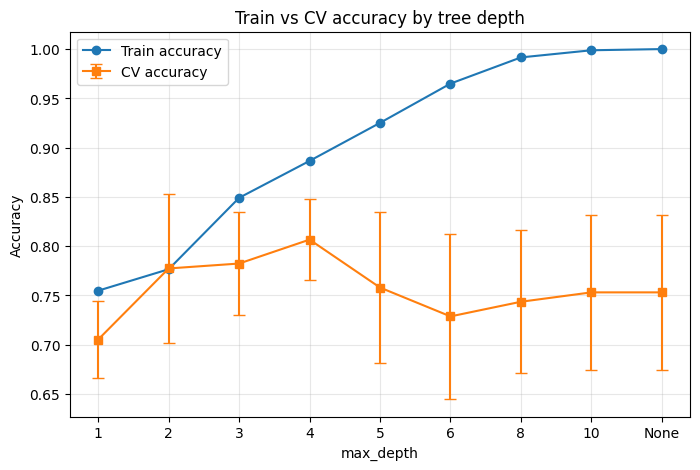

In [46]:
import matplotlib.pyplot as plt

x = range(len(depths))
labels = ["None" if d is None else str(d) for d in depths]

plt.figure(figsize=(8, 5))
plt.errorbar(x, sweep_df["train_acc"], label="Train accuracy", marker="o", capsize=4)
plt.errorbar(x, sweep_df["cv_acc"], yerr=sweep_df["cv_std"],
             label="CV accuracy", marker="s", capsize=4)
plt.xticks(x, labels)
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Train vs CV accuracy by tree depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [47]:
# Find the best CV accuracy and its std
best_idx = sweep_df["cv_acc"].idxmax()
best_cv = sweep_df.loc[best_idx, "cv_acc"]
best_std = sweep_df.loc[best_idx, "cv_std"]
threshold = best_cv - best_std

print(f"Best CV accuracy: {best_cv:.4f} (std {best_std:.4f})")
print(f"Threshold (best − std): {threshold:.4f}")
print()
print("Depths with cv_acc >= threshold:")
for _, row in sweep_df.iterrows():
    mark = "✓" if row["cv_acc"] >= threshold else " "
    print(f"  {mark} max_depth={row['max_depth']:>4}  cv_acc={row['cv_acc']:.4f}  std={row['cv_std']:.4f}")

Best CV accuracy: 0.8066 (std 0.0414)
Threshold (best − std): 0.7653

Depths with cv_acc >= threshold:
    max_depth=   1  cv_acc=0.7052  std=0.0395
  ✓ max_depth=   2  cv_acc=0.7774  std=0.0754
  ✓ max_depth=   3  cv_acc=0.7823  std=0.0520
  ✓ max_depth=   4  cv_acc=0.8066  std=0.0414
    max_depth=   5  cv_acc=0.7580  std=0.0768
    max_depth=   6  cv_acc=0.7287  std=0.0839
    max_depth=   8  cv_acc=0.7436  std=0.0728
    max_depth=  10  cv_acc=0.7531  std=0.0790
    max_depth=None  cv_acc=0.7531  std=0.0790


In [48]:
msl_values = [1, 2, 5, 10, 20, 40]
sweep_msl = []

for msl in msl_values:
    model = DecisionTreeClassifier(
        criterion="entropy", max_depth=None,
        min_samples_leaf=msl, random_state=SEED
    )
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring="accuracy", return_train_score=True
    )
    model.fit(X_train, y_train)
    n_leaves = model.get_n_leaves()

    sweep_msl.append({
        "min_samples_leaf": msl,
        "n_leaves": n_leaves,
        "train_acc": scores["train_score"].mean(),
        "cv_acc": scores["test_score"].mean(),
        "cv_std": scores["test_score"].std(),
    })

sweep_msl_df = pd.DataFrame(sweep_msl)
print(sweep_msl_df.round(4).to_string(index=False))

 min_samples_leaf  n_leaves  train_acc  cv_acc  cv_std
                1        32     1.0000  0.7531  0.0790
                2        31     0.9601  0.7531  0.0676
                5        19     0.8889  0.7580  0.0482
               10        12     0.8490  0.7676  0.0605
               20         7     0.7790  0.7774  0.0754
               40         4     0.7548  0.7052  0.0395


In [50]:
best_idx = sweep_df["cv_acc"].idxmax()
best_cv = sweep_df.loc[best_idx, "cv_acc"]
best_std = sweep_df.loc[best_idx, "cv_std"]
threshold = best_cv - best_std

print(f"Best CV accuracy: {best_cv:.4f} (at max_depth={sweep_df.loc[best_idx,'max_depth']}, std {best_std:.4f})")
print(f"Threshold (best − std): {threshold:.4f}")
print()
print("Depths with cv_acc >= threshold:")
for _, row in sweep_df.iterrows():
    mark = "✓" if row["cv_acc"] >= threshold else " "
    print(f"  {mark} max_depth={row['max_depth']:>4}  cv_acc={row['cv_acc']:.4f}")

Best CV accuracy: 0.8066 (at max_depth=4, std 0.0414)
Threshold (best − std): 0.7653

Depths with cv_acc >= threshold:
    max_depth=   1  cv_acc=0.7052
  ✓ max_depth=   2  cv_acc=0.7774
  ✓ max_depth=   3  cv_acc=0.7823
  ✓ max_depth=   4  cv_acc=0.8066
    max_depth=   5  cv_acc=0.7580
    max_depth=   6  cv_acc=0.7287
    max_depth=   8  cv_acc=0.7436
    max_depth=  10  cv_acc=0.7531
    max_depth=None  cv_acc=0.7531


In [51]:
import numpy as np


chosen_depth = 2


final_model = DecisionTreeClassifier(
    criterion="entropy", max_depth=chosen_depth, random_state=SEED
)
final_model.fit(X_train, y_train)


y_pred = final_model.predict(X_test)
p = (y_pred == y_test).mean()
n = len(y_test)
se = np.sqrt(p * (1 - p) / n)

print(f"Chosen model: max_depth={chosen_depth}")
print(f"Test accuracy: {p:.4f}")
print(f"Standard error: {se:.4f}")
print(f"Test set size: {n}")

Chosen model: max_depth=2
Test accuracy: 0.7778
Standard error: 0.0438
Test set size: 90


# Part 4 — Tree or logistic regression?

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


tree_chosen = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)

tree_unlimited = DecisionTreeClassifier(criterion="entropy", max_depth=None, random_state=SEED)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

models = {
    "Tree (depth 2)": tree_chosen,
    "Tree (unlimited)": tree_unlimited,
    "Logistic Regression": logreg,
}

results = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=("accuracy", "f1")
    )
    results.append({
        "Model": name,
        "CV accuracy (mean)": scores["test_accuracy"].mean(),
        "CV accuracy (std)": scores["test_accuracy"].std(),
        "CV F1 (mean)": scores["test_f1"].mean(),
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

              Model  CV accuracy (mean)  CV accuracy (std)  CV F1 (mean)
     Tree (depth 2)              0.7774             0.0754        0.7612
   Tree (unlimited)              0.7531             0.0790        0.7329
Logistic Regression              0.8114             0.0667        0.7968


In [53]:

tree_raw = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)
tree_raw.fit(X_train, y_train)
preds_raw = tree_raw.predict(X_test)


scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)

tree_scaled = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)
tree_scaled.fit(X_train_scaled, y_train)
preds_scaled = tree_scaled.predict(X_test_scaled)


agreement = (preds_raw == preds_scaled).mean()
print(f"Agreement between raw and scaled tree: {agreement:.4f}")

Agreement between raw and scaled tree: 1.0000


In [54]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix


tree_final = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)
tree_final.fit(X_train, y_train)
tree_preds = tree_final.predict(X_test)


logreg_final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
logreg_final.fit(X_train, y_train)
logreg_preds = logreg_final.predict(X_test)

for name, preds in [("Tree (depth 2)", tree_preds), ("Logistic Regression", logreg_preds)]:
    acc = accuracy_score(y_test, preds)
    f1  = f1_score(y_test, preds)
    cm  = confusion_matrix(y_test, preds)
    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1:       {f1:.4f}")
    print(f"Confusion matrix:")
    print(f"  TN={cm[0,0]:3d}  FP={cm[0,1]:3d}")
    print(f"  FN={cm[1,0]:3d}  TP={cm[1,1]:3d}")
    print()

--- Tree (depth 2) ---
Accuracy: 0.7778
F1:       0.7561
Confusion matrix:
  TN= 39  FP=  9
  FN= 11  TP= 31

--- Logistic Regression ---
Accuracy: 0.8778
F1:       0.8675
Confusion matrix:
  TN= 43  FP=  5
  FN=  6  TP= 36



### Conclusion

I would use **logistic regression** (with standardization) on this data.

The CV table shows logistic regression with the highest mean CV accuracy (0.8114) and F1
(0.7968), followed by the depth-2 tree (0.7774 and 0.7612). However, the difference in CV
accuracy (0.034) is **smaller than the CV standard deviation** of both models (0.067–0.075),
so on cross-validation alone I cannot tell them apart from noise.

The hold-out test tells a clearer story: logistic regression achieves accuracy 0.8778 and
F1 0.8675, while the depth-2 tree reaches only 0.7778 and 0.7561. The difference (0.100 in
accuracy) is **larger than the standard error of the test accuracy** (~0.035 for logistic
regression, ~0.044 for the tree), so on this test split logistic regression is genuinely
better — not just noise.

The confusion matrix confirms this: the tree makes 11 false negatives (missed patients
with disease), while logistic regression makes only 6, and the tree also makes more false
positives (9 vs 5).

I would not use the unlimited-depth tree: it overfits (train accuracy ≈ 1.0, CV accuracy
0.753) and performs worse than both other models on every metric.

# Part 5 — Reading a tree, and reproducibility

In [55]:
from sklearn.tree import export_text

shallow = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=SEED).fit(X_train, y_train)
print(export_text(shallow, feature_names=feature_names))

ranked = sorted(zip(shallow.feature_importances_, feature_names), reverse=True)
print()
print("Top 5 feature importances:")
for imp, name in ranked[:5]:
    print(f"  {name:10s}  {float(imp):.3f}")

|--- ca <= 0.50
|   |--- thal <= 6.50
|   |   |--- oldpeak <= 2.70
|   |   |   |--- class: 0
|   |   |--- oldpeak >  2.70
|   |   |   |--- class: 1
|   |--- thal >  6.50
|   |   |--- thalach <= 144.50
|   |   |   |--- class: 1
|   |   |--- thalach >  144.50
|   |   |   |--- class: 0
|--- ca >  0.50
|   |--- cp <= 3.50
|   |   |--- slope <= 1.50
|   |   |   |--- class: 0
|   |   |--- slope >  1.50
|   |   |   |--- class: 1
|   |--- cp >  3.50
|   |   |--- oldpeak <= 0.40
|   |   |   |--- class: 1
|   |   |--- oldpeak >  0.40
|   |   |   |--- class: 1


Top 5 feature importances:
  ca          0.351
  thal        0.203
  cp          0.188
  oldpeak     0.128
  slope       0.069


In [59]:
for imp, name in ranked:
    print(f"{name:10s}  {float(imp):.4f}")

ca          0.3512
thal        0.2028
cp          0.1877
oldpeak     0.1276
slope       0.0695
thalach     0.0612
trestbps    0.0000
sex         0.0000
restecg     0.0000
fbs         0.0000
exang       0.0000
chol        0.0000
age         0.0000


In [56]:
tree = shallow.tree_
for i in range(tree.node_count):
    indent = "  " * int(np.argmax(tree.children_left == i) if False else 0)
    left = tree.children_left[i]
    right = tree.children_right[i]
    is_leaf = (left == -1 and right == -1)
    kind = "LEAF" if is_leaf else f"split on {feature_names[tree.feature[i]]} <= {tree.threshold[i]:.2f}"
    print(f"node {i}: n={tree.n_node_samples[i]:3d}  {kind}")

node 0: n=207  split on ca <= 0.50
node 1: n=128  split on thal <= 6.50
node 2: n= 90  split on oldpeak <= 2.70
node 3: n= 85  LEAF
node 4: n=  5  LEAF
node 5: n= 38  split on thalach <= 144.50
node 6: n= 16  LEAF
node 7: n= 22  LEAF
node 8: n= 79  split on cp <= 3.50
node 9: n= 29  split on slope <= 1.50
node 10: n= 16  LEAF
node 11: n= 13  LEAF
node 12: n= 50  split on oldpeak <= 0.40
node 13: n= 13  LEAF
node 14: n= 37  LEAF


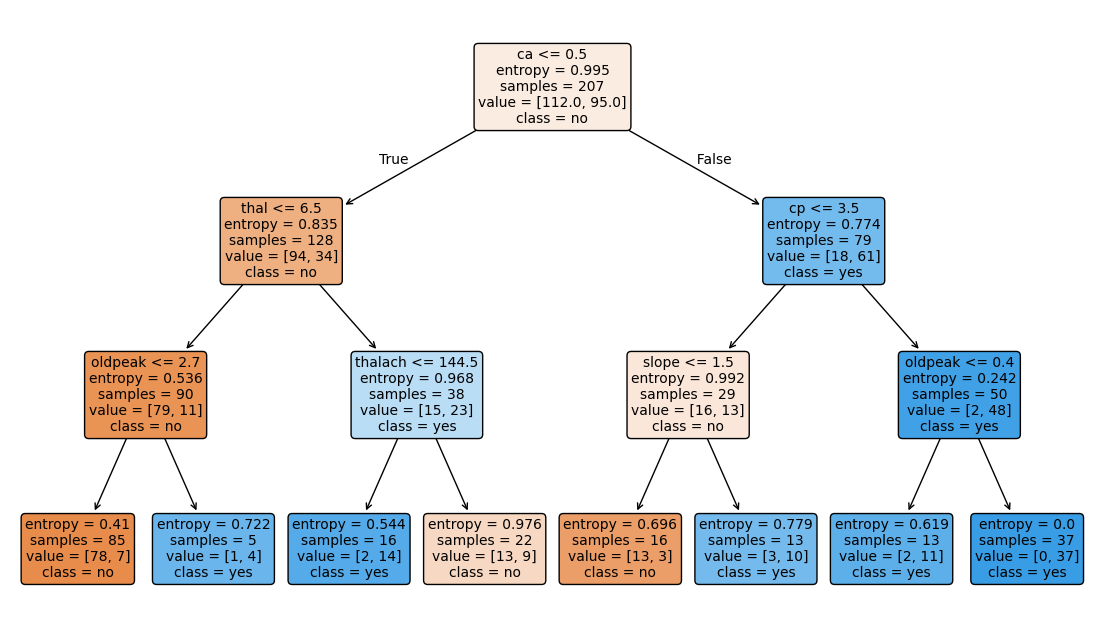

In [57]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
plot_tree(
    shallow, feature_names=feature_names, class_names=["no", "yes"],
    filled=True, rounded=True, fontsize=10
)
plt.show()

In [58]:
print(ranked[:5])

[(np.float64(0.35120623672689133), 'ca'), (np.float64(0.20281217228482215), 'thal'), (np.float64(0.18772122089138493), 'cp'), (np.float64(0.12760578102095937), 'oldpeak'), (np.float64(0.06948597978408533), 'slope')]


### Top 5 feature importances

1. `ca` — 0.3512
2. `thal` — 0.2028
3. `cp` — 0.1877
4. `oldpeak` — 0.1276
5. `slope` — 0.0695

**Limitation of `feature_importances_`:** it measures how much a feature reduces impurity
across the whole tree, but it does **not** show the direction of the effect (whether a high
value increases or decreases the risk). Two features that are correlated can also split the
importance between them, making each look less important than it really is.